# **INTRODUCTION TO PANDAS**
---
<img src="Imperial_logo.png" align = "left" width=200>
 <br><br>
 
- Copyright (c) Antoine Jacquier, 2024. All rights reserved

- Author: Jack Jacquier <a.jacquier@imperial.ac.uk>

- Platform: Tested on Windows 10 with Python 3.9

 **Origins**
 
 `pandas` was originally developed by [Wes McKinney](https://wesmckinney.com) while at AQR Capital in 2007-2010.

# Introduction to DataFrames

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pylab as plt
%matplotlib inline

## Create a Dataframe with dates

We start by creating series of Gaussian distributed values.

In [2]:
N = 10000 ## size of the dataframe

In [3]:
xx = np.random.standard_normal((N, 5))
df = pd.DataFrame(xx)

In [4]:
type(df)

pandas.DataFrame

In [5]:
df.head() ## Print the top five rows

,0,1,2,3,4
0,0.156654,0.113850,0.769391,-0.305126,-1.148367
1,1.147037,1.058769,-1.253212,-1.577502,1.553100
2,0.436399,-0.271196,0.715673,1.451424,-2.285835
3,1.333977,1.296510,0.578529,-0.449551,-0.720819
4,0.380650,1.037107,-0.869744,-0.888702,-1.090973


In [6]:
df.tail() ## Print the bottom five rows

,0,1,2,3,4
9995,-0.272410,-0.723430,-0.019751,-0.232881,-1.639064
9996,0.293629,1.906799,-0.601881,-0.880816,-0.592463
9997,0.276212,-0.013249,1.835593,-0.708693,1.148703
9998,0.566646,-1.796079,0.967462,-0.929709,0.858548
9999,-1.380714,-2.372049,0.328477,-0.225382,1.238158


In [7]:
df.columns = ["Series 1", "Series 2", "Series 3", "Series 4", "Series 5"]
## Or more concisely:
#df.columns = ["Series %s" % i  for i in range(1,6)]
df.head()

,Series 1,Series 2,Series 3,Series 4,Series 5
0,0.156654,0.113850,0.769391,-0.305126,-1.148367
1,1.147037,1.058769,-1.253212,-1.577502,1.553100
2,0.436399,-0.271196,0.715673,1.451424,-2.285835
3,1.333977,1.296510,0.578529,-0.449551,-0.720819
4,0.380650,1.037107,-0.869744,-0.888702,-1.090973


Note that the index (first column on the left) has no real meaning here. 
However, in practice, thinking or each other column as time series, it may represent dates. 
We re-index the whole dataframe with this in mind.

#### Specifying a start date

In [8]:
startYear = '2018'
startMonth = '01'
startDay = '01'
startDate = startYear + "-" + startMonth + "-" + startDay ## string concatenation
print("Start date: ", startDate)

Start date:  2018-01-01


In [9]:
dates = pd.date_range(startDate, periods=N, freq="D")
df.index = dates
df.index.name = 'Date'
df.head()

,Series 1,Series 2,Series 3,Series 4,Series 5
Date,,,,,
2018-01-01,0.156654,0.113850,0.769391,-0.305126,-1.148367
2018-01-02,1.147037,1.058769,-1.253212,-1.577502,1.553100
2018-01-03,0.436399,-0.271196,0.715673,1.451424,-2.285835
2018-01-04,1.333977,1.296510,0.578529,-0.449551,-0.720819
2018-01-05,0.380650,1.037107,-0.869744,-0.888702,-1.090973


## Basic dataframe manipulations

In [10]:
df.keys()

Index(['Series 1', 'Series 2', 'Series 3', 'Series 4', 'Series 5'], dtype='str')

An Index is a `pandas` class for an immutable sequence, which is the basis for axes.

In [11]:
print('Names of columns:', [d for d in df.keys().values])
## similarly df.columns

Names of columns: ['Series 1', 'Series 2', 'Series 3', 'Series 4', 'Series 5']


Overview of the data

In [12]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 10000 entries, 2018-01-01 to 2045-05-18
Freq: D
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Series 1  10000 non-null  float64
 1   Series 2  10000 non-null  float64
 2   Series 3  10000 non-null  float64
 3   Series 4  10000 non-null  float64
 4   Series 5  10000 non-null  float64
dtypes: float64(5)
memory usage: 468.8 KB


Basic statistics

In [13]:
df.describe()

,Series 1,Series 2,Series 3,Series 4,Series 5
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,-0.015575,-0.001218,0.004530,-0.011255,0.004078
std,1.007787,0.989641,0.990953,1.000900,0.993376
min,-4.146879,-3.325169,-3.505661,-3.962672,-3.284368
25%,-0.692214,-0.666494,-0.674110,-0.680466,-0.675295
50%,-0.007423,0.002628,0.008802,-0.012818,0.006878
75%,0.668471,0.658744,0.677383,0.662774,0.673248
max,3.603722,3.848700,3.472018,4.009398,3.858140


## Accessing elements from a dataframe

A  DataFrame may be indexed like an array, specifying the row and column number using .iloc (index location).
The location can be called either by the index number or by its name.

In [14]:
df.head()

,Series 1,Series 2,Series 3,Series 4,Series 5
Date,,,,,
2018-01-01,0.156654,0.113850,0.769391,-0.305126,-1.148367
2018-01-02,1.147037,1.058769,-1.253212,-1.577502,1.553100
2018-01-03,0.436399,-0.271196,0.715673,1.451424,-2.285835
2018-01-04,1.333977,1.296510,0.578529,-0.449551,-0.720819
2018-01-05,0.380650,1.037107,-0.869744,-0.888702,-1.090973


In [15]:
print("First row, second column: ", df.iloc[0, 1], " or ", df.loc[startDate, 'Series 2'])

First row, second column:  0.11385039601538728  or  0.11385039601538728


In [16]:
myRow = df.iloc[2,:]
print(myRow)
print("Type: ", type(myRow))

Series 1    0.436399
Series 2   -0.271196
Series 3    0.715673
Series 4    1.451424
Series 5   -2.285835
Name: 2018-01-03 00:00:00, dtype: float64
Type:  <class 'pandas.Series'>


Equivalently:

In [17]:
myRow = df.loc['2018-01-03']
print(myRow, type(myRow))

Series 1    0.436399
Series 2   -0.271196
Series 3    0.715673
Series 4    1.451424
Series 5   -2.285835
Name: 2018-01-03 00:00:00, dtype: float64 <class 'pandas.Series'>


In [18]:
print("Accessing elements by slicing over columns: ")
print(df.iloc[0, 1:3])
print(type(df.iloc[0, 1:3]))

Accessing elements by slicing over columns: 
Series 2    0.113850
Series 3    0.769391
Name: 2018-01-01 00:00:00, dtype: float64
<class 'pandas.Series'>


In [19]:
print("Accessing elements by slicing over rows: ")
print(df.iloc[10:14, 1])
print(type(df.iloc[10:14, 1]))

Accessing elements by slicing over rows: 
Date
2018-01-11    1.210442
2018-01-12   -0.318139
2018-01-13    0.273520
2018-01-14    1.396178
Freq: D, Name: Series 2, dtype: float64
<class 'pandas.Series'>


In [20]:
print("Accessing elements by slicing over boths: ")
print(df.iloc[10:14, 1:3])
print(type(df.iloc[10:14, 1:3]))

Accessing elements by slicing over boths: 
            Series 2  Series 3
Date                          
2018-01-11  1.210442  0.035796
2018-01-12 -0.318139  0.714704
2018-01-13  0.273520  1.248148
2018-01-14  1.396178  1.072497
<class 'pandas.DataFrame'>


Question: What are the types of the following objects:
- df.iloc[2]
- df.iloc[2].values
- [d for d in df.iloc[2]]

In [21]:
print(type(df.iloc[2]))
print(type(df.iloc[2].values))
print(type([d for d in df.iloc[2]]))

<class 'pandas.Series'>
<class 'numpy.ndarray'>
<class 'list'>


### `.at` and `.iat`

These two commands are very similar to `.loc` and `.iloc`, and are actually faster, but slicing is not permitted.

In [22]:
%timeit df.iloc[10, 2]
%timeit df.iat[10, 2]

10.1 μs ± 336 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)
3.8 μs ± 47.3 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)


In [24]:
# no slices allowed!
df.iat[10, 2:4]

ValueError: iAt based indexing can only have integer indexers

### Extract elements with conditions

In [25]:
mySeriesName = "Series 2"
df[df[mySeriesName] > 3.4]

,Series 1,Series 2,Series 3,Series 4,Series 5
Date,,,,,
2025-02-05,-0.170262,3.848700,0.422167,0.210175,-0.126877
2044-07-22,0.584950,3.492503,0.932315,-0.810045,0.482043


Note that the series `df` has not been modified. Only a copy has been printed!!

In [26]:
mySeries =  df[mySeriesName][df[mySeriesName] > 3.4]
mySeries

Date
2025-02-05    3.848700
2044-07-22    3.492503
Name: Series 2, dtype: float64

We can return the series only as a list:

In [27]:
print(mySeries.values)

[3.84869967 3.49250316]


### User-defined functions

In [28]:
df = df
df.head()

,Series 1,Series 2,Series 3,Series 4,Series 5
Date,,,,,
2018-01-01,0.156654,0.113850,0.769391,-0.305126,-1.148367
2018-01-02,1.147037,1.058769,-1.253212,-1.577502,1.553100
2018-01-03,0.436399,-0.271196,0.715673,1.451424,-2.285835
2018-01-04,1.333977,1.296510,0.578529,-0.449551,-0.720819
2018-01-05,0.380650,1.037107,-0.869744,-0.888702,-1.090973


Here, the original dataframe has been modified!

In [29]:
def myFunction(x, param):
    return x - param

df[mySeriesName] = df[mySeriesName].apply(myFunction, args=(10,))
df.head()

,Series 1,Series 2,Series 3,Series 4,Series 5
Date,,,,,
2018-01-01,0.156654,-9.886150,0.769391,-0.305126,-1.148367
2018-01-02,1.147037,-8.941231,-1.253212,-1.577502,1.553100
2018-01-03,0.436399,-10.271196,0.715673,1.451424,-2.285835
2018-01-04,1.333977,-8.703490,0.578529,-0.449551,-0.720819
2018-01-05,0.380650,-8.962893,-0.869744,-0.888702,-1.090973


## Numpy on dataframe

This is where the power of the DataFrame comes into the picture, namely that operations need to be performed element by element, 
but apply to a whole series (column) at once.

In [30]:
myIndex = input("Series index")

Series index 1


In [31]:
ser = 'Series ' + myIndex
print('Maximum on the first Series:', df[ser].max())
print('Date (index) where this maximum is attained:', df[ser].argmax()) ## deprecated
print('Date where this maximum is attained:', df[ser].idxmax(), df.index[df[ser].argmax()])
print('Mean of the first series:', df[ser].mean())

Maximum on the first Series: 3.603722281346864
Date (index) where this maximum is attained: 9749
Date where this maximum is attained: 2044-09-10 00:00:00 2044-09-10 00:00:00
Mean of the first series: -0.015574570654047892


We can also obtain general results about the whole dataframe / each series in the dataframe:

In [32]:
df.mean()

Series 1    -0.015575
Series 2   -10.001218
Series 3     0.004530
Series 4    -0.011255
Series 5     0.004078
dtype: float64

## Plotting Dataframes

##### Plot all the time series

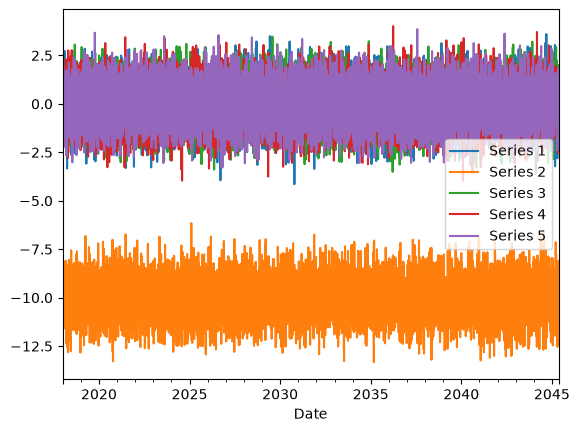

In [33]:
df.plot();

**WHAT IS WRONG WITH THE PLOT?**

##### Plot one column at a time

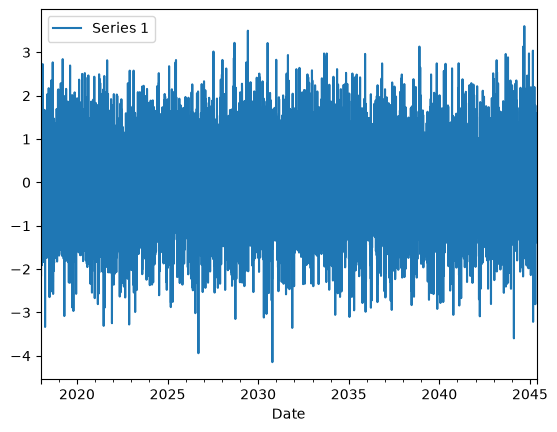

In [34]:
df[ser].plot(legend=ser);

##### Changing the type of plots

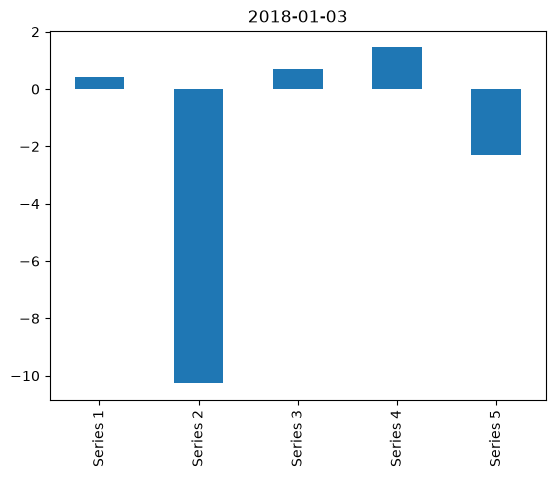

In [35]:
datePlot = '2018-01-03'
df.loc[datePlot].plot(kind='bar', title=datePlot); ## for one particular day

## Sorting DataFrames

In [36]:
print('Data sorted by ' + ser)
df.sort_values(by=ser).head()

Data sorted by Series 1


,Series 1,Series 2,Series 3,Series 4,Series 5
Date,,,,,
2030-10-15,-4.146879,-9.002158,1.243542,0.350064,-1.300236
2026-09-15,-3.940963,-8.825161,-1.742063,0.363778,0.382674
2044-02-13,-3.597463,-10.205546,-0.101245,-1.758367,0.727724
2031-11-20,-3.357300,-9.563121,-0.008772,1.040063,0.842827
2018-03-30,-3.335637,-9.159503,-0.938927,-1.123815,-0.573654


*WARNING: the dataframe df itself has remained unchanged though...*

In [37]:
df.head()

,Series 1,Series 2,Series 3,Series 4,Series 5
Date,,,,,
2018-01-01,0.156654,-9.886150,0.769391,-0.305126,-1.148367
2018-01-02,1.147037,-8.941231,-1.253212,-1.577502,1.553100
2018-01-03,0.436399,-10.271196,0.715673,1.451424,-2.285835
2018-01-04,1.333977,-8.703490,0.578529,-0.449551,-0.720819
2018-01-05,0.380650,-8.962893,-0.869744,-0.888702,-1.090973


## Renaming columns

In [40]:
df.rename(columns={'Series 1': 'SPX', 
                   'Series 2': 'DAX', 
                   'Series 3': 'GOOGL', 
                   'Series 4': 'AAPL', 
                   'Series 5': 'VIX'})
df.head()

,SPX,DAX,GOOGL,AAPL,VIX
Date,,,,,
2018-01-01,0.156654,-9.886150,0.769391,-0.305126,-1.148367
2018-01-02,1.147037,-8.941231,-1.253212,-1.577502,1.553100
2018-01-03,0.436399,-10.271196,0.715673,1.451424,-2.285835
2018-01-04,1.333977,-8.703490,0.578529,-0.449551,-0.720819
2018-01-05,0.380650,-8.962893,-0.869744,-0.888702,-1.090973


### A note on copies on slices....

In [41]:
df.head()

,SPX,DAX,GOOGL,AAPL,VIX
Date,,,,,
2018-01-01,0.156654,-9.886150,0.769391,-0.305126,-1.148367
2018-01-02,1.147037,-8.941231,-1.253212,-1.577502,1.553100
2018-01-03,0.436399,-10.271196,0.715673,1.451424,-2.285835
2018-01-04,1.333977,-8.703490,0.578529,-0.449551,-0.720819
2018-01-05,0.380650,-8.962893,-0.869744,-0.888702,-1.090973


In [42]:
val = df.iloc[1,0]
val

np.float64(1.1470371409101372)

In [43]:
df[df["SPX"] == val]["DAX"] = 0.
df

C:\cygwin64\tmp\ipykernel_428\3746132791.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment.
Such chained assignment never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

Try using '.loc[row_indexer, col_indexer] = value' instead, to perform the assignment in a single step.

See the documentation for a more detailed explanation: https://pandas.pydata.org/docs/dev/user_guide/migration.html#chained-assignment
  df[df["SPX"] == val]["DAX"] = 0.


,SPX,DAX,GOOGL,AAPL,VIX
Date,,,,,
2018-01-01,0.156654,-9.886150,0.769391,-0.305126,-1.148367
2018-01-02,1.147037,-8.941231,-1.253212,-1.577502,1.553100
2018-01-03,0.436399,-10.271196,0.715673,1.451424,-2.285835
2018-01-04,1.333977,-8.703490,0.578529,-0.449551,-0.720819
2018-01-05,0.380650,-8.962893,-0.869744,-0.888702,-1.090973
...,...,...,...,...,...
2045-05-14,-0.272410,-10.723430,-0.019751,-0.232881,-1.639064
2045-05-15,0.293629,-8.093201,-0.601881,-0.880816,-0.592463
2045-05-16,0.276212,-10.013249,1.835593,-0.708693,1.148703


In [44]:
df.loc[df["SPX"] == val, "DAX"] = 0.
df

,SPX,DAX,GOOGL,AAPL,VIX
Date,,,,,
2018-01-01,0.156654,-9.886150,0.769391,-0.305126,-1.148367
2018-01-02,1.147037,0.000000,-1.253212,-1.577502,1.553100
2018-01-03,0.436399,-10.271196,0.715673,1.451424,-2.285835
2018-01-04,1.333977,-8.703490,0.578529,-0.449551,-0.720819
2018-01-05,0.380650,-8.962893,-0.869744,-0.888702,-1.090973
...,...,...,...,...,...
2045-05-14,-0.272410,-10.723430,-0.019751,-0.232881,-1.639064
2045-05-15,0.293629,-8.093201,-0.601881,-0.880816,-0.592463
2045-05-16,0.276212,-10.013249,1.835593,-0.708693,1.148703


# Working with real data

## Financial data from Yahoo Finance

In [46]:
# ! pip install pandas_datareader

In [47]:
import pandas as pd
pd.core.common.is_list_like = pd.api.types.is_list_like
import pandas_datareader as web
from pandas_datareader import data as pdr
from datetime import datetime
import yfinance as yf

In [49]:
import warnings
from pandas.errors import Pandas4Warning
warnings.filterwarnings("ignore", category=Pandas4Warning, message=".*inplace.*")

ticker = "AAPL"

# download apple data for a specific daterange
df_share = yf.download("AAPL", start="2000-01-01", end="2024-01-01")
df_share.head()

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2000-01-03,0.837002,0.841208,0.760359,0.784193,535796800
2000-01-04,0.766435,0.827188,0.756620,0.809430,512377600
2000-01-05,0.777650,0.826721,0.770173,0.775781,778321600
2000-01-06,0.710354,0.800083,0.710354,0.793540,767972800
2000-01-07,0.744002,0.755219,0.714093,0.721570,460734400


In [50]:
df_share.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 6037 entries, 2000-01-03 to 2023-12-29
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   (Close, AAPL)   6037 non-null   float64
 1   (High, AAPL)    6037 non-null   float64
 2   (Low, AAPL)     6037 non-null   float64
 3   (Open, AAPL)    6037 non-null   float64
 4   (Volume, AAPL)  6037 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 283.0 KB


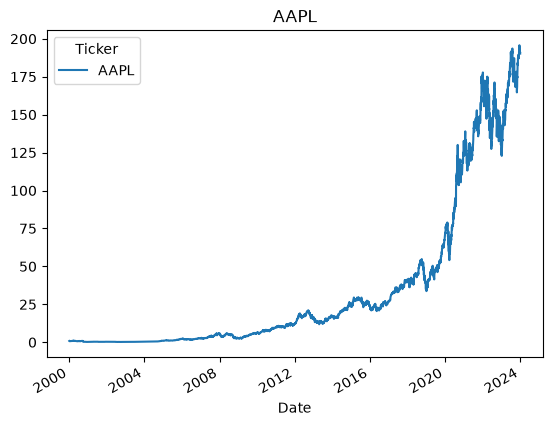

In [51]:
df_share["Close"].plot(title=ticker)
plt.show()

## Economics Data from FRED

In [52]:
from datetime import date
series_code = 'DGS10' # 10-year Treasury Rate
data_source = 'fred' # FED Economic Data Service
start = date(1962, 1, 1)
myData = pdr.DataReader(series_code, data_source, start)

In [53]:
myData.head()

,DGS10
DATE,
1962-01-02,4.06
1962-01-03,4.03
1962-01-04,3.99
1962-01-05,4.02
1962-01-08,4.03


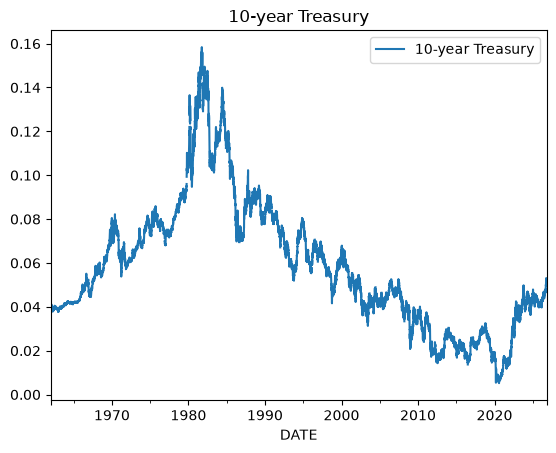

In [54]:
myData = myData / 100.
series_name = '10-year Treasury'
myData = myData.rename(columns={series_code: series_name})
myData.plot(title=series_name)
plt.show() 

## Analysing real data

In [56]:
# ticker = "^GSPC" ## S&P500 
# GSPC : Global Standard & Poor’s Composite
spx = yf.download("^GSPC", start="2020-01-01", end="2024-01-01")
spx.head()

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC
Date,,,,,
2020-01-02,3257.850098,3258.139893,3235.530029,3244.669922,3459930000
2020-01-03,3234.850098,3246.149902,3222.340088,3226.360107,3484700000
2020-01-06,3246.280029,3246.840088,3214.639893,3217.550049,3702460000
2020-01-07,3237.179932,3244.909912,3232.429932,3241.860107,3435910000
2020-01-08,3253.050049,3267.070068,3236.669922,3238.590088,3726840000


In [57]:
spx.head()

Price,Close,High,Low,Open,Volume
Ticker,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC
Date,,,,,
2020-01-02,3257.850098,3258.139893,3235.530029,3244.669922,3459930000
2020-01-03,3234.850098,3246.149902,3222.340088,3226.360107,3484700000
2020-01-06,3246.280029,3246.840088,3214.639893,3217.550049,3702460000
2020-01-07,3237.179932,3244.909912,3232.429932,3241.860107,3435910000
2020-01-08,3253.050049,3267.070068,3236.669922,3238.590088,3726840000


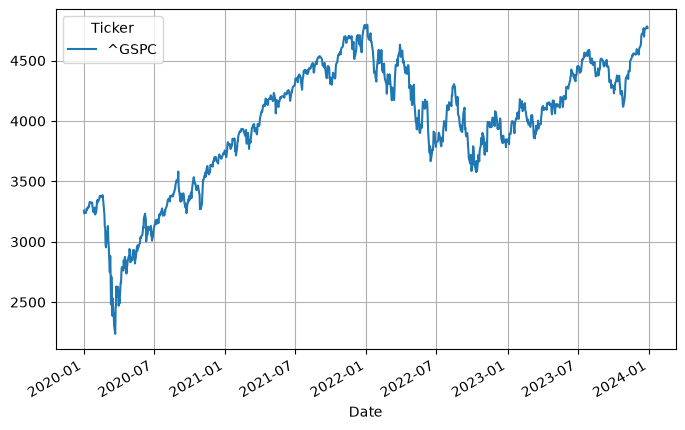

In [58]:
spx['Close'].plot(figsize=(8, 5), grid=True);

### A quick note on computation time -- computing daily returns

In [59]:
len(spx)

1006

In [61]:
spx.head()

Price,Close,High,Low,Open,Volume,ReturnsLoop
Ticker,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC,
Date,,,,,,
2020-01-02,3257.850098,3258.139893,3235.530029,3244.669922,3459930000,0.0
2020-01-03,3234.850098,3246.149902,3222.340088,3226.360107,3484700000,0.0
2020-01-06,3246.280029,3246.840088,3214.639893,3217.550049,3702460000,0.0
2020-01-07,3237.179932,3244.909912,3232.429932,3241.860107,3435910000,0.0
2020-01-08,3253.050049,3267.070068,3236.669922,3238.590088,3726840000,0.0


In [60]:
%%time
spx['ReturnsLoop'] = 0.
for i in range(1, len(spx)):
    spx['ReturnsLoop'][i] = np.log(spx['Close'][i] / spx['Close'][i - 1])

<timed exec>:1: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.


CPU times: total: 15.6 ms
Wall time: 6.59 ms


KeyError: 1

In [ ]:
spx[['Close', 'ReturnsLoop']].head()

In [ ]:
%time spx['Returns'] = np.log(spx['Close'] / spx['Close'].shift(1))
spx[['Close', 'Returns']].head()

In [ ]:
del spx['ReturnsLoop']

In [ ]:
spx = spx.dropna()
spx.head()

In [ ]:
val = df.iloc[0,0]
val

In [ ]:
df[df['SPX'] == val]['DAX'] = 0.
df.head()

In [ ]:
df.loc[df['SPX'] == val, 'DAX'] = 0.
df.head()

**WHAT IS THE PROBLEM?**

### Data analysis

In [62]:
spx[['close', 'Returns']].plot(subplots=True, style='b',figsize=(8, 6));

KeyError: "['close' 'Returns'] not in index"

**Remarks:**
- Volatility clustering
- Leverage effect

### Moving averages

In [63]:
n1, n2 = 24, 252
MA1, MA2 = 'MA' + str(n1) + 'd', 'MA' + str(n2) + 'd'
spx[MA1] = spx['Close'].rolling(window=n1, center = False).mean()
spx[MA2] = spx['Close'].rolling(window=n2, center = False).mean()
spx.tail()

C:\cygwin64\tmp\ipykernel_428\3608207413.py:3: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  spx[MA1] = spx['Close'].rolling(window=n1, center = False).mean()
C:\cygwin64\tmp\ipykernel_428\3608207413.py:4: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  spx[MA2] = spx['Close'].rolling(window=n2, center = False).mean()


Price,Close,High,Low,Open,Volume,ReturnsLoop,MA24d,MA252d
Ticker,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC,,,
Date,,,,,,,,
2023-12-22,4754.629883,4772.939941,4736.770020,4753.919922,3046770000,0.0,4625.697896,4265.044879
2023-12-26,4774.750000,4784.720215,4758.450195,4758.859863,2513910000,0.0,4635.171651,4268.824086
2023-12-27,4781.580078,4785.390137,4768.899902,4773.450195,2748450000,0.0,4645.312907,4272.541388
2023-12-28,4783.350098,4793.299805,4780.979980,4786.439941,2698860000,0.0,4654.759989,4276.327499
2023-12-29,4769.830078,4788.430176,4751.990234,4782.879883,3126060000,0.0,4663.530416,4280.242619


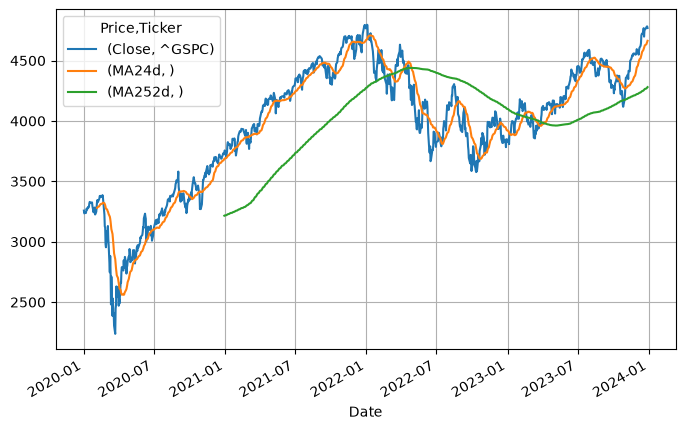

In [64]:
spx[['Close', MA1, MA2]].plot(figsize=(8, 5), grid=True);

In [65]:
spx['MovingReturnsVol'] = spx['Returns'].rolling(window=252).std() * np.sqrt(252.)

KeyError: 'Returns'

In [ ]:
spx[['Close', 'Returns', 'MovingReturnsVol']].plot(subplots=True, style='b',figsize=(8, 7), grid=True);

# The `groupby` command

In [66]:
import pandas as pd

file_name = "https://github.com/tdhadfield/MATH_70112/raw/main/Class.xlsx"
df = pd.read_excel(file_name)
df.head()

,Name,Grade,Nationality,Gender
0,John,81.791817,China,M
1,Joe,96.101421,UK,M
2,Jack,96.466640,France,F
3,Ben,93.981908,US,M
4,Cynthia,53.858965,Japan,M


In [ ]:
df.info()

In [ ]:
df["Grade"].mean()

In [ ]:
df["Grade"].sum()# / len(df.index)

In [ ]:
df.groupby(['Nationality']).agg({'Grade': 'mean'})

In [ ]:
df.groupby(['Nationality']).agg({'Grade': 'sum'})

In [ ]:
df.groupby(['Nationality', 'Gender']).agg({'Grade': 'mean'})#.sum()

**WHAT IS HAPPENING????**

# Merge, join, concatenate data -- an example with the MTA database

NYC map: https://www.google.com/maps/place/New+York,+NY,+USA/@40.6976684,-74.2605634,10z/data=!3m1!4b1!4m5!3m4!1s0x89c24fa5d33f083b:0xc80b8f06e177fe62!8m2!3d40.7127753!4d-74.0059728


Data: http://web.mta.info/developers/turnstile.html



### Importing and looking at the data

In [ ]:
import datetime as dt
import pandas as pd

In [ ]:
url  = r'http://web.mta.info/developers/data/nyct/turnstile/turnstile_180825.txt'
df = pd.read_csv(url)#, index_col=0, header=0, parse_dates=True)

In [ ]:
df.info()

In [ ]:
df.head()

In [ ]:
#!pip install xlrd

In [ ]:
url  = r'http://web.mta.info/developers/resources/nyct/turnstile/Remote-Booth-Station.xls'
infoStations = pd.read_excel(url)#, index_col=0, header=0, parse_dates=True)
infoStations.head()

### Cleaning the data

In [ ]:
df['ENTRIES'].max()

In [ ]:
df['EXITS'].max()

In [ ]:
df.keys()

In [ ]:
df.columns = ['ca', 'unit', 'scp', 'station', 'linename', 'division', 'date','time', 'desc', 'entries','exits']

In [ ]:
df['exits'].max()

In [ ]:
#df["date"] = pd.to_datetime(df["date"] + " " + df["time"])
df["date"] = pd.to_datetime(df["date"])
df.head()

### Counting daily traffic using `groupbby`

In [ ]:
df_entries = df.groupby(['station','ca','unit','scp','date']).entries.max() - df.groupby(['station','ca','unit','scp','date']).entries.min()
df_exits = df.groupby(['station','ca','unit','scp','date']).exits.max() - df.groupby(['station','ca','unit','scp','date']).exits.min()
print("Types: ", type(df_entries), type(df_exits))

In [ ]:
df_entries[:10]

We are now going to merge `df_entries` and `df_exits`. However, they need to have the same index.
https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.merge.html

In [ ]:
df_entries_flat = df_entries.reset_index()
df_exits_flat = df_exits.reset_index()

In [ ]:
df_entries_flat.head()

In [ ]:
df_traffic = pd.merge(df_entries_flat, df_exits_flat, how='outer')
df_traffic.head()

In [ ]:
df_traffic['day'] = df_traffic['date'].dt.day_name()
df_traffic['traffic'] = df_traffic['entries'] + df_traffic['exits']

In [ ]:
df_traffic.head()

In [ ]:
#df_traffic[["entries", "exits"]].hist();
df_traffic[["traffic"]].hist();

In [ ]:
thresholdMax = 25000

df_traffic = df_traffic[df_traffic["traffic"] < thresholdMax]
#df_traffic = df_traffic[df_traffic["traffic"] > thresholdMax]
df_traffic["logtraffic"] = np.log(np.abs(np.maximum(df_traffic["traffic"], 1E-3)))

In [ ]:
df_traffic["logtraffic"].hist();

Final steps

In [ ]:
df_station = df_traffic.groupby(['station','date','day']).sum().reset_index()
df_station.head()

### What happens at Penn station?

In [ ]:
df_station["station"].unique()

In [ ]:
df_Penn = df_station[df_station["station"] == "42 ST-PORT AUTH"]
df_Penn
df_Penn.plot.bar(x="day", y="traffic");

### Exercise

- What are the 3 busiest stations on average?
- What is the traffic distribution over the week?
- What are the busiest stations on weekends and on weekdays?

### Exercise

Write a script that imports each weekly file http://web.mta.info/developers/turnstile.html and merges them.

# Common issues

In [ ]:
xx = [2, 4, 6, '8']
df = pd.DataFrame(xx)
df.columns = ["X"]
df.head()

In [ ]:
df["Mult"] = 2.*df["X"]

In [ ]:
df.info()

In [ ]:
df['X'] = pd.to_numeric(df['X'])
df["Mult"] = 2.*df["X"]

In [ ]:
df.info()

In [ ]:
df.head()

### Working with copies

In [ ]:
N = 5
xx = np.random.standard_normal((N, 5))
df = pd.DataFrame(xx)
df.head()

In [ ]:
df2 = df ### same as df.copy(deep=False)
df3 = df.copy(deep=True)

In [ ]:
i,j = 0,1
df.iat[i,j] = 2.
print(df.iat[i,j], df2.iat[i,j])

In [ ]:
i,j = 0,1
df3.iat[i,j] = 5.
print(df.iat[i,j], df3.iat[i,j])

### Filling the void

In [69]:
file_name = "https://github.com/tdhadfield/MATH_70112/raw/main/EURGBP-2020-01.csv"

df = pd.read_csv(file_name) #"../Data files/eurgbp-1m.csv", sep=";")#,header = None)
df.head()
df.columns=["Date", "Time", "Bid", "Ask", "na", "na2", "na3"]
#df["DateTime"] = df["Date"] + df["Time"]
df = df.drop(columns=['na', 'na2', 'na3'])
df.head()

ValueError: Length mismatch: Expected axis has 4 elements, new values have 7 elements

**Exercise:** Create a dataframe with one value for the bid and one value for the ask for each day.
For example, using the maximum value of the day.

In [70]:
import random
chosenDay = df.iloc[random.choice(range(len(df))), 0]
print("Chosen day: ", chosenDay)

Chosen day:  EUR/GBP


In [71]:
oneDay = df[df["Date"] == chosenDay]
oneDay.set_index("Time", inplace=True)
del oneDay["Date"]
oneDay.plot(title="eurgbp on " + chosenDay);
oneDay.head()

KeyError: 'Date'

In [72]:
nbMissingValues = len(oneDay)//3
N = len(oneDay)
listMissingValues = random.choices(range(N), k=nbMissingValues)
for l in listMissingValues:
    oneDay.iat[l, 0] = np.log(-1.)

NameError: name 'oneDay' is not defined

In [ ]:
oneDay.head()

In [ ]:
oneDay["Bid"].plot()

How do we fill the gaps? 
- `dropna`?
- interpolation? But which one?

In [ ]:
oneDay["Bid"].interpolate(method='linear', axis=0).plot();

# Extra: Combining DataFrames and creating signals

In [ ]:
import yahoo_fin.stock_info as si

aapl = si.get_data("AAPL", start_date = "01/01/1980", end_date = "01/31/2024")
coke = si.get_data("COKE", start_date = "01/01/1980", end_date = "01/31/2024")

In [ ]:
aapl.tail()

In [ ]:
coke.tail()

In [ ]:
df = pd.merge(coke, aapl, left_index=True, right_index=True)
df.head()

In [ ]:
df = pd.merge(coke["close"], aapl["close"], left_index=True, right_index=True)
df.columns = ["coke", "aapl"]
df.head()

In [ ]:
df.plot();

#### Normalised versions...

In [ ]:
coke = coke["close"] 
aapl = aapl["close"] 

In [ ]:
coke0 = coke.iloc[0]
aapl0 = aapl.iloc[0]

coke_norm = coke / coke0
aapl_norm = aapl / aapl0
df_norm = pd.merge(coke_norm, aapl_norm, left_index=True, right_index=True)
df_norm.columns = ["coke norm", "aapl norm"]
df_norm.plot();

In [ ]:
coke = si.get_data("COKE", start_date = "01/01/1980", end_date = "01/31/2024")

In [ ]:
coke["Returns"] = np.log(coke['close'] / coke['close'].shift(1))
coke['MovingVol'] = coke['Returns'].rolling(window=252).std() * np.sqrt(252.)
coke = coke[["close", "Returns", "MovingVol"]]
coke = coke.dropna()
coke["MovingVol"].plot(title="Moving vol");

In [ ]:
maxVolAllowed = 0.4
coke.loc[coke['MovingVol'] > maxVolAllowed, 'Signal'] = 0.6#coke["MovingVol"].max()
coke[["Signal", "MovingVol"]].plot().legend(loc=3);

# WARNINGS: Data inconsistencies

- Missing data
- NaN, -1, ...
- Date format
- Blank spaces
- Formats: Int, float, ...